# code_121 · Forecast origins, future covariates and demand baselines

**Book:** section 24.1. A self-contained forecasting laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_24_GUIDE.md), [run evidence](../CHAPTER_24_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_121).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2721;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
import statsmodels
VERSIONS['statsmodels']=statsmodels.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2721


<a id="forecast-origin-contract"></a>
 ## Every forecast names an origin and information cutoff
 Generate sixteen building-demand series at hourly frequency for ninety days. A forecast issued at index o can observe demand/weather only through o−1 and predicts o through o+23. Context budget is 48 hours; daily phase, scheduled occupancy and building scale are known. A fixed synthetic weather provider knows its seasonal mean and AR coefficient, and issues conditional expectations from the latest observed weather deviation. It never reads realized future weather. Fit before hour1200, choose settings on origins1200–1536 with targets ending before1560, and assess origins1560–2136 with targets ending at2160. Rolling contexts refresh admitted actual observations between origins, with frozen model parameters. Compare persistence, previous-day and previous-week seasonal naive, per-building direct Ridge, shared direct Ridge and shared one-step Ridge rolled recursively. All identities occur in training; this tests later-time forecasting, not unseen-building transfer.


,method,final_MSE,horizon_1_MSE,horizon_6_MSE,horizon_24_MSE
0,Persistence,7.993172,1.182683,4.334060,11.334058
1,Seasonal naive,9.304228,9.749173,11.421627,11.334058
2,Weekly naive,4.546387,2.420193,6.511222,3.326019
3,Local direct,2.138517,1.146368,2.669946,2.619180
4,Global direct,2.099402,1.128029,2.651092,2.414738
5,Global recursive,1.836063,0.780853,2.185082,1.980754


,family,alpha,development_MSE
0,Local direct,1.0,3.062634
1,Local direct,100.0,2.189866
2,Global direct,1.0,3.203809
3,Global direct,100.0,2.220529
4,Global recursive,1.0,1.647103
5,Global recursive,100.0,1.670563


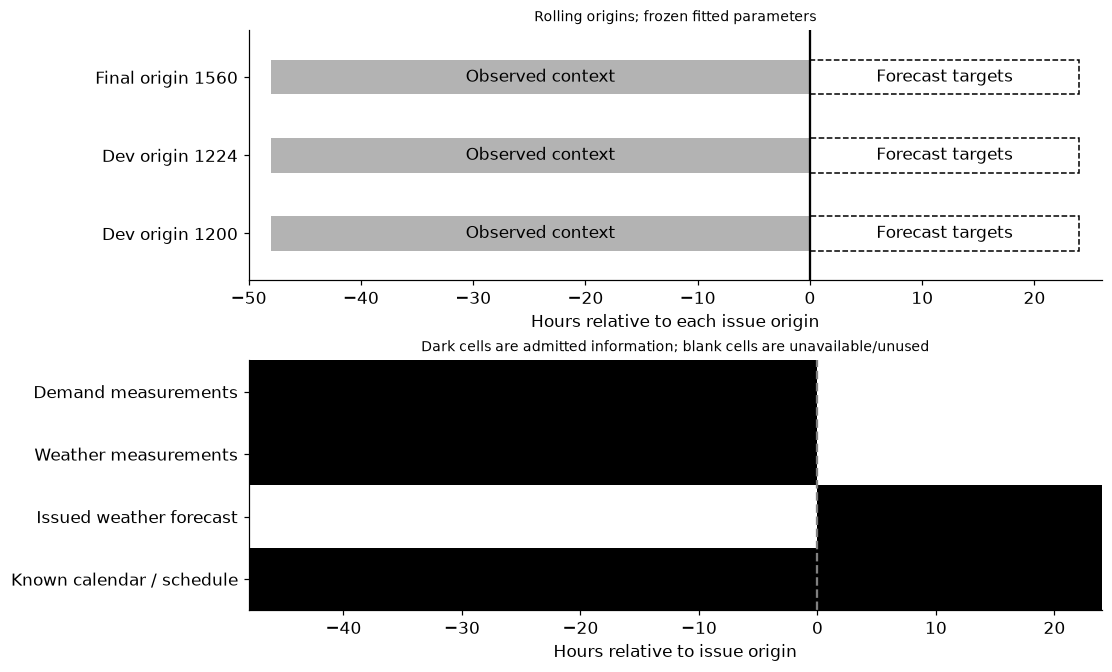

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from matplotlib.patches import Rectangle
B,T,H,L=16,2160,24,48;clock=np.arange(T);hour=clock%24;weekday=(clock//24)%7;occupancy=((hour>=8)&(hour<18)&(weekday<5)).astype(float);weather_mean=12+5*np.sin(2*np.pi*clock/(24*7));weather_deviation=np.zeros(T)
for t in range(1,T):weather_deviation[t]=.85*weather_deviation[t-1]+rng.normal(0,.8)
weather=weather_mean+weather_deviation;area=rng.uniform(.8,1.2,B);offset=rng.normal(0,1.5,B);residual=np.zeros((B,T))
for t in range(1,T):residual[:,t]=.6*residual[:,t-1]+rng.normal(0,.4,B)
base=10+3*occupancy+1.5*np.sin(2*np.pi*hour/24)+.6*np.cos(2*np.pi*hour/24)+1.2*np.maximum(12-weather,0);energy=offset[:,None]+area[:,None]*base+residual;identity=np.eye(B)
def issued_weather(origin,horizon,observed=weather):
    times=np.arange(origin,origin+horizon);known_mean=12+5*np.sin(2*np.pi*times/(24*7));latest_mean=12+5*np.sin(2*np.pi*(origin-1)/(24*7));return known_mean+.85**np.arange(1,horizon+1)*(observed[origin-1]-latest_mean)
def direct_features(origins,observed_energy=energy,observed_weather=weather,invalid_realized_weather=False):
    values=[]
    for origin in origins:
        times=origin+np.arange(H);forecast=observed_weather[times] if invalid_realized_weather else issued_weather(origin,H,observed_weather);future=np.r_[np.sin(2*np.pi*(times%24)/24),np.cos(2*np.pi*(times%24)/24),occupancy[times],np.maximum(12-forecast,0)]
        row=np.c_[observed_energy[:,origin-24:origin],observed_energy[:,origin-np.array([1,2,24,48])],area[:,None]*future[None,:],area,identity];values.append(row)
    return np.concatenate(values)
def outcomes(origins):return np.concatenate([energy[:,origin:origin+H] for origin in origins])
train_origins=np.arange(48,1200-H+1,24);dev_origins=np.arange(1200,1560-H+1,24);final_origins=np.arange(1560,T-H+1,24);train_x=direct_features(train_origins);train_y=outcomes(train_origins);dev_x=direct_features(dev_origins);dev_y=outcomes(dev_origins);final_x=direct_features(final_origins);final_y=outcomes(final_origins);training_owner=np.tile(np.arange(B),len(train_origins));development_owner=np.tile(np.arange(B),len(dev_origins));final_owner=np.tile(np.arange(B),len(final_origins));predictions={};candidates=[];chosen_models={}
for family in ['Local direct','Global direct']:
    best=np.inf
    for alpha in [1.,100.]:
        if family=='Global direct':model=make_pipeline(StandardScaler(),Ridge(alpha=alpha));model.fit(train_x,train_y);prediction=model.predict(dev_x);models=model
        else:
            models={};prediction=np.empty_like(dev_y)
            for b in range(B):
                selected=training_owner==b;model=make_pipeline(StandardScaler(),Ridge(alpha=alpha));model.fit(train_x[selected,:-B],train_y[selected]);models[b]=model;prediction[development_owner==b]=model.predict(dev_x[development_owner==b,:-B])
        score=float(np.mean((prediction-dev_y)**2));candidates.append({'family':family,'alpha':alpha,'development_MSE':score})
        if score<best:best=score;chosen=(alpha,models)
    alpha,models=chosen;chosen_models[family]=models
    if family=='Global direct':predictions[family]=models.predict(final_x)
    else:
        prediction=np.empty_like(final_y)
        for b in range(B):prediction[final_owner==b]=models[b].predict(final_x[final_owner==b,:-B])
        predictions[family]=prediction
def one_features(history,t,weather_forecast):
    known=np.array([np.sin(2*np.pi*(t%24)/24),np.cos(2*np.pi*(t%24)/24),occupancy[t],max(12-weather_forecast,0)]);return np.c_[history[:,t-np.array([1,2,24,48])],area[:,None]*known[None,:],area,identity]
one_x=np.concatenate([one_features(energy,t,issued_weather(t,1)[0]) for t in range(48,1200)]);one_y=np.concatenate([energy[:,t] for t in range(48,1200)])
def recursive_forecast(model,origins,observed_energy=energy):
    values=[]
    for origin in origins:
        history=observed_energy[:,:origin].copy();forecast_weather=issued_weather(origin,H)
        for horizon in range(H):
            t=origin+horizon;prediction=model.predict(one_features(history,t,forecast_weather[horizon]));history=np.c_[history,prediction]
        values.append(history[:,origin:origin+H])
    return np.concatenate(values)
best=np.inf
for alpha in [1.,100.]:
    model=make_pipeline(StandardScaler(),Ridge(alpha=alpha));model.fit(one_x,one_y);prediction=recursive_forecast(model,dev_origins);score=float(np.mean((prediction-dev_y)**2));candidates.append({'family':'Global recursive','alpha':alpha,'development_MSE':score})
    if score<best:best=score;recursive_model=model;recursive_alpha=alpha
predictions['Global recursive']=recursive_forecast(recursive_model,final_origins);predictions['Persistence']=np.concatenate([np.repeat(energy[:,o-1,None],H,axis=1) for o in final_origins]);predictions['Seasonal naive']=np.concatenate([energy[:,o-24:o] for o in final_origins]);predictions['Weekly naive']=np.concatenate([energy[:,o-168:o-168+H] for o in final_origins]);rows=[]
for name in ['Persistence','Seasonal naive','Weekly naive','Local direct','Global direct','Global recursive']:
    error=(predictions[name]-final_y)**2;rows.append({'method':name,'final_MSE':float(error.mean()),'MSE_by_horizon':error.mean(0).tolist(),'horizon_1_MSE':float(error[:,0].mean()),'horizon_6_MSE':float(error[:,5].mean()),'horizon_24_MSE':float(error[:,23].mean())})
# Future changes alter targets, but cannot alter issued features or frozen recursive inputs.
origin=int(final_origins[0]);changed_weather=weather.copy();changed_weather[origin:]+=1000;changed_energy=energy.copy();changed_energy[:,origin:]+=1000;np.testing.assert_array_equal(issued_weather(origin,H,changed_weather),issued_weather(origin,H));np.testing.assert_array_equal(direct_features([origin],changed_energy,changed_weather),direct_features([origin]));np.testing.assert_array_equal(recursive_forecast(recursive_model,[origin],changed_energy),recursive_forecast(recursive_model,[origin]))
invalid=chosen_models['Global direct'].predict(direct_features(final_origins,invalid_realized_weather=True));invalid_RMS=float(np.sqrt(np.mean((invalid-predictions['Global direct'])**2)));assert invalid_RMS>0 and train_origins.max()+H<=1200 and dev_origins.max()+H<=1560 and final_origins.max()+H<=T
RESULTS.update(comparisons=rows,candidates=candidates,building_count=B,hourly_length=T,context_hours=L,horizon_hours=H,origin_counts={'train':len(train_origins),'development':len(dev_origins),'final':len(final_origins)},cutoffs={'fit_end_exclusive':1200,'final_begin':1560},direct_feature_count=train_x.shape[1],recursive_feature_count=one_x.shape[1],training_counts={'direct_context_rows':len(train_x),'direct_scalar_targets':train_y.size,'recursive_context_rows':len(one_x),'recursive_scalar_targets':len(one_y)},fitted_linear_coefficients_and_intercepts={'Local direct':sum(m.named_steps['ridge'].coef_.size+m.named_steps['ridge'].intercept_.size for m in chosen_models['Local direct'].values()),'Global direct':chosen_models['Global direct'].named_steps['ridge'].coef_.size+chosen_models['Global direct'].named_steps['ridge'].intercept_.size,'Global recursive':recursive_model.named_steps['ridge'].coef_.size+np.size(recursive_model.named_steps['ridge'].intercept_)},recursive_selected_alpha=recursive_alpha,future_weather_perturbation_changes_issued_forecast=False,future_energy_perturbation_changes_frozen_forecast=False,invalid_realized_weather_substitution_prediction_RMS=invalid_RMS,weather_provider_AR=.85);display(pd.DataFrame([{k:v for k,v in r.items() if k!='MSE_by_horizon'} for r in rows]));display(pd.DataFrame(candidates))
fig,axes=plt.subplots(2,1,figsize=(10,6));ax=axes[0]
for i,o in enumerate([1200,1224,1560]):ax.add_patch(Rectangle((-48,i-.22),48,.44,facecolor='.7'));ax.add_patch(Rectangle((0,i-.22),24,.44,facecolor='white',edgecolor='black',linestyle='--'));ax.text(-24,i,'Observed context',ha='center',va='center');ax.text(12,i,'Forecast targets',ha='center',va='center')
ax.axvline(0,color='black');ax.set(xlim=(-50,26),ylim=(-.6,2.6),yticks=range(3),yticklabels=['Dev origin 1200','Dev origin 1224','Final origin 1560'],xlabel='Hours relative to each issue origin',title='Rolling origins; frozen fitted parameters')
available=np.array([[1]*48+[0]*24,[1]*48+[0]*24,[0]*48+[1]*24,[1]*72]);axes[1].imshow(available,aspect='auto',cmap='Greys',vmin=0,vmax=1,extent=(-48,24,3.5,-.5));axes[1].axvline(0,color='.5',linestyle='--');axes[1].set(yticks=range(4),yticklabels=['Demand measurements','Weather measurements','Issued weather forecast','Known calendar / schedule'],xlabel='Hours relative to issue origin',title='Dark cells are admitted information; blank cells are unavailable/unused');plt.show()


<a id="forecast-information-limits"></a>
 ## Direct heads and recursive lags use different fitted rules
 Direct models map one admitted context and all known-future covariates to 24 outputs. Local models have their own scaler/coefficients; the global model shares coefficients with a known-building indicator vocabulary. Recursion fits one-step targets, then feeds predicted demand back into later lag features, while keeping the original issued weather trajectory. It never refreshes future realized weather inside the forecast. Replacing that trajectory with realized weather changes predictions, but is explicitly an invalid information substitution, not an admitted winning comparator. Test origins update context using measurements that have actually arrived since the previous issue; that is different from refitting coefficients or observing targets within one forecast. Error is reported by horizon and over the same final origins/buildings. The direct design has 768 context rows with 24 scalar outputs each; the recursive design uses the same 18,432 scalar source targets in hourly one-step contexts. Their coefficient counts differ sharply and are reported. A weekly naive baseline was added during authoring to expose the generator's known weekly calendar; original fitted models/results remain frozen. Repeated and overlapping targets are dependent, and a small numerical advantage is not an independent-cohort significance claim.


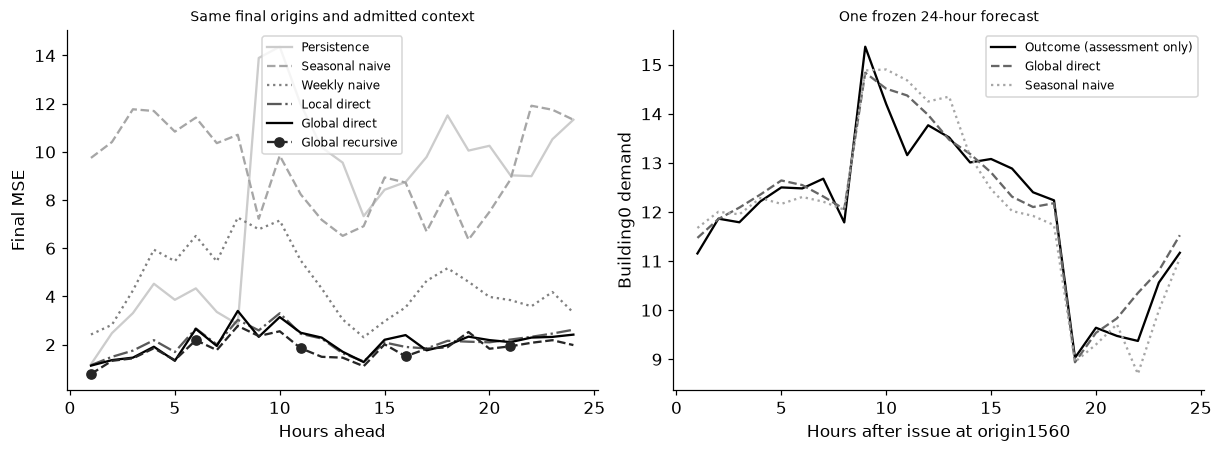

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4));styles=['-','--',':','-.','-','--'];shades=['.8','.65','.5','.35','black','.15']
for index,row in enumerate(rows):axes[0].plot(np.arange(1,H+1),row['MSE_by_horizon'],linestyle=styles[index],color=shades[index],marker='o' if row['method']=='Global recursive' else None,markevery=5,label=row['method'])
axes[0].set(xlabel='Hours ahead',ylabel='Final MSE',title='Same final origins and admitted context');axes[0].legend(fontsize=8)
axes[1].plot(np.arange(1,H+1),final_y[0],color='black',label='Outcome (assessment only)');axes[1].plot(np.arange(1,H+1),predictions['Global direct'][0],'--',color='.4',label='Global direct');axes[1].plot(np.arange(1,H+1),predictions['Seasonal naive'][0],':',color='.65',label='Seasonal naive');axes[1].set(xlabel='Hours after issue at origin1560',ylabel='Building0 demand',title='One frozen 24-hour forecast');axes[1].legend(fontsize=8);plt.show()
assert all(np.isfinite(r['final_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_121','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual temporal forecast contract', 'persistence and seasonal references', 'local versus shared direct Ridge', 'recursive forecast with predicted lags', 'weather-prefix and future-target access audits'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual temporal forecast contract", "persistence and seasonal references", "local versus shared direct Ridge", "recursive forecast with predicted lags", "weather-prefix and future-target access audits"], "elapsed_seconds": 1.094, "example_id": "code_121", "hardware": "Darwin arm64 CPU", "results": {"building_count": 16, "candidates": [{"alpha": 1.0, "development_MSE": 3.0626338988912583, "family": "Local direct"}, {"alpha": 100.0, "development_MSE": 2.1898655402487077, "family": "Local direct"}, {"alpha": 1.0, "development_MSE": 3.2038091825866735, "family": "Global direct"}, {"alpha": 100.0, "development_MSE": 2.2205293629598413, "family": "Global direct"}, {"alpha": 1.0, "development_MSE": 1.6471032479975674, "family": "Global recursive"}, {"alpha": 100.0, "development_MSE": 1.6705627832870333, "family": "Global recursive"}], "comparisons": [{"MSE_by_horizon": [1.1826834443647314, 2.476653370767406, 3.3076054177192358, 4.526521330533